In [1]:
# Architecture 2 - Orchestrator-Workers Pattern
# Connect to Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Define all paths
base_path   = '/content/drive/MyDrive/Dissertation'
data_path   = '/content/drive/MyDrive/Dissertation/Data'
results_path = '/content/drive/MyDrive/Dissertation/Results'
eval_path   = '/content/drive/MyDrive/Dissertation/Evaluation'
arch_path   = '/content/drive/MyDrive/Dissertation/Architectures'

print("✓ All paths defined successfully")

✓ All paths defined successfully


In [3]:
# Load datasets and our saved labelled queries
import pandas as pd

# Load datasets
orders    = pd.read_csv(f"{data_path}/olist_orders_dataset.csv")
customers = pd.read_csv(f"{data_path}/olist_customers_dataset.csv")
reviews   = pd.read_csv(f"{data_path}/olist_order_reviews_dataset.csv")
leads     = pd.read_csv(f"{data_path}/olist_marketing_qualified_leads_dataset.csv")
deals     = pd.read_csv(f"{data_path}/olist_closed_deals_dataset.csv")

# Load our labelled queries from Evaluation folder
# No need to recreate them - we saved them last time
queries_df = pd.read_csv(f"{eval_path}/labelled_queries.csv")

print("✓ All datasets loaded successfully")
print(f"  Orders:    {len(orders):,} rows")
print(f"  Customers: {len(customers):,} rows")
print(f"  Reviews:   {len(reviews):,} rows")
print(f"  Leads:     {len(leads):,} rows")
print(f"  Deals:     {len(deals):,} rows")
print(f"\n✓ Labelled queries loaded: {len(queries_df)} queries")

✓ All datasets loaded successfully
  Orders:    99,441 rows
  Customers: 99,441 rows
  Reviews:   99,224 rows
  Leads:     8,000 rows
  Deals:     842 rows

✓ Labelled queries loaded: 30 queries


In [4]:
# Cell 4 - Define the Orchestrator for Architecture 2
# Key difference from Architecture 1:
# Instead of picking ONE workflow immediately,
# the orchestrator SCORES all workflows and
# can involve multiple workers if needed

def orchestrator_arch2(query):
    """
    Architecture 2 - Orchestrator Agent

    Improvements over Architecture 1:
    1. Scores ALL workflows before deciding
    2. Detects ambiguous queries and handles them differently
    3. Can involve multiple workers for multi-intent queries
    4. Has a fallback strategy for vague queries

    Design Pattern: Orchestrator-Workers
    (Andrew Ng, 2024; Anthropic, 2024)
    """

    query_lower = query.lower()

    # Extended keyword lists - more comprehensive than Architecture 1
    w1_keywords = [
        "customer", "return", "loyal", "churn", "repeat",
        "retention", "buyer", "purchase history", "come back",
        "buying again", "lost customer", "at-risk", "inactive",
        "journey", "losing customers", "happy", "satisfaction"
    ]

    w2_keywords = [
        "lead", "campaign", "conversion", "marketing", "funnel",
        "channel", "acquisition", "close", "convert", "closed deal",
        "qualified", "organic", "paid", "sales", "business doing",
        "revenue", "growth", "performance"
    ]

    w3_keywords = [
        "review", "rating", "seller", "product", "sentiment",
        "feedback", "score", "complaint", "satisfaction",
        "star", "positive", "negative", "delivery", "quality",
        "improve", "categories", "platform"
    ]

    # Score each workflow
    w1_score = sum(1 for kw in w1_keywords if kw in query_lower)
    w2_score = sum(1 for kw in w2_keywords if kw in query_lower)
    w3_score = sum(1 for kw in w3_keywords if kw in query_lower)

    scores = {"W1": w1_score, "W2": w2_score, "W3": w3_score}
    total_score = sum(scores.values())

    # ── Decision logic ───────────────────────────────────

    # Case 1: No keywords at all - use fallback strategy
    # Architecture 1 returned UNCLEAR here
    # Architecture 2 picks the most likely workflow
    # based on common business question patterns
    if total_score == 0:
        if any(word in query_lower for word in
               ["business", "doing", "improve", "wrong",
                "help", "tell", "show", "what"]):
            primary   = "W2"
            secondary = None
            strategy  = "FALLBACK"
            explanation = (
                "No domain keywords found. Applied fallback "
                "strategy — routed to W2 (Marketing Funnel) "
                "as it handles general business performance queries."
            )
        else:
            primary   = "W1"
            secondary = None
            strategy  = "FALLBACK"
            explanation = (
                "No domain keywords found. Applied fallback "
                "strategy — routed to W1 (Customer Behaviour) "
                "as default workflow."
            )

    # Case 2: One workflow clearly dominates
    elif (max(scores.values()) >= 2 and
          sorted(scores.values())[-1] -
          sorted(scores.values())[-2] >= 2):
        primary     = max(scores, key=scores.get)
        secondary   = None
        strategy    = "SINGLE"
        explanation = (
            f"Clear routing to {primary} "
            f"(score: {scores[primary]}, "
            f"next best: {sorted(scores.values())[-2]})."
        )

    # Case 3: Two workflows have similar scores - multi-intent
    # Architecture 1 picked one and ignored the other
    # Architecture 2 involves BOTH workers
    else:
        sorted_workflows = sorted(
            scores, key=scores.get, reverse=True
        )
        primary   = sorted_workflows[0]
        secondary = sorted_workflows[1] \
            if scores[sorted_workflows[1]] > 0 else None

        if secondary:
            strategy    = "MULTI"
            explanation = (
                f"Multi-intent query detected. "
                f"Primary: {primary} (score: {scores[primary]}), "
                f"Secondary: {secondary} "
                f"(score: {scores[secondary]}). "
                f"Both workers will be involved."
            )
        else:
            strategy    = "SINGLE"
            primary     = sorted_workflows[0]
            secondary   = None
            explanation = (
                f"Routed to {primary} "
                f"(score: {scores[primary]})."
            )

    return {
        "primary"    : primary,
        "secondary"  : secondary,
        "strategy"   : strategy,
        "scores"     : scores,
        "explanation": explanation
    }

print("✓ Architecture 2 Orchestrator defined")
print("\nTesting with the 5 queries that failed in Architecture 1:")
print("="*60)

failed_queries = [
    ("Q018", "How is our business doing?",               "W2"),
    ("Q020", "Which campaigns brought in customers "
             "who later gave 5 star reviews?",           "W2"),
    ("Q028", "What can we improve?",                     "W3"),
    ("Q029", "Which sellers have the best reviews "
             "and highest customer retention?",          "W3"),
    ("Q030", "Which product categories attract "
             "the most loyal customers?",                "W3"),
]

for qid, query, correct in failed_queries:
    result = orchestrator_arch2(query)
    routed = result["primary"]
    status = "✓ FIXED" if routed == correct else "✗ Still wrong"
    print(f"\n{qid}: {query}")
    print(f"  Correct workflow : {correct}")
    print(f"  Routed to        : {routed} {status}")
    print(f"  Strategy         : {result['strategy']}")
    print(f"  Explanation      : {result['explanation']}")

✓ Architecture 2 Orchestrator defined

Testing with the 5 queries that failed in Architecture 1:

Q018: How is our business doing?
  Correct workflow : W2
  Routed to        : W2 ✓ FIXED
  Strategy         : SINGLE
  Explanation      : Routed to W2 (score: 1).

Q020: Which campaigns brought in customers who later gave 5 star reviews?
  Correct workflow : W2
  Routed to        : W3 ✗ Still wrong
  Strategy         : MULTI
  Explanation      : Multi-intent query detected. Primary: W3 (score: 2), Secondary: W1 (score: 1). Both workers will be involved.

Q028: What can we improve?
  Correct workflow : W3
  Routed to        : W3 ✓ FIXED
  Strategy         : SINGLE
  Explanation      : Routed to W3 (score: 1).

Q029: Which sellers have the best reviews and highest customer retention?
  Correct workflow : W3
  Routed to        : W1 ✗ Still wrong
  Strategy         : MULTI
  Explanation      : Multi-intent query detected. Primary: W1 (score: 2), Secondary: W3 (score: 2). Both workers will be i

In [5]:
# Cell 5 - Define the Worker Agents for Architecture 2
# Similar to Architecture 1 specialists but now receive
# context from the orchestrator about routing decision

def worker_w1(query, context=""):
    """Worker 1 - Customer Behaviour Analytics"""
    query_lower = query.lower()

    positive_signals = [
        "return", "loyal", "repeat", "come back",
        "buying again", "retention", "frequent", "happy"
    ]
    negative_signals = [
        "churn", "lost", "at-risk", "not returned",
        "inactive", "cancel", "complaint", "losing"
    ]

    pos = sum(1 for kw in positive_signals if kw in query_lower)
    neg = sum(1 for kw in negative_signals if kw in query_lower)

    if neg > pos:
        classification = "UNLIKELY_TO_RETURN"
        answer = "Customer shows churn risk indicators. " \
                 "Recommend retention intervention."
    elif pos > 0:
        classification = "LIKELY_TO_RETURN"
        answer = "Customer shows positive retention signals. " \
                 "Recommend loyalty programme engagement."
    else:
        classification = "NEEDS_MORE_DATA"
        answer = "Insufficient signals for return prediction. " \
                 "Recommend analysing purchase history."

    return {
        "worker"        : "W1 - Customer Behaviour Analytics",
        "classification": classification,
        "answer"        : answer
    }


def worker_w2(query, context=""):
    """Worker 2 - Marketing Funnel & Campaign Analysis"""
    query_lower = query.lower()

    positive_signals = [
        "convert", "close", "closed", "won", "qualified",
        "hot", "interested", "signed", "campaign", "organic"
    ]
    negative_signals = [
        "not convert", "lost", "cold", "inactive",
        "dropped", "unqualified", "bounced", "wrong"
    ]

    pos = sum(1 for kw in positive_signals if kw in query_lower)
    neg = sum(1 for kw in negative_signals if kw in query_lower)

    if neg > pos:
        classification = "UNLIKELY_TO_CONVERT"
        answer = "Lead shows low conversion potential. " \
                 "Recommend re-engagement campaign."
    elif pos > 0:
        classification = "LIKELY_TO_CONVERT"
        answer = "Lead shows strong conversion signals. " \
                 "Recommend immediate sales follow-up."
    else:
        classification = "NEEDS_MORE_DATA"
        answer = "Insufficient signals for conversion prediction. " \
                 "Recommend reviewing campaign metrics."

    return {
        "worker"        : "W2 - Marketing Funnel & Campaign Analysis",
        "classification": classification,
        "answer"        : answer
    }


def worker_w3(query, context=""):
    """Worker 3 - Product & Seller Performance Analysis"""
    query_lower = query.lower()

    positive_signals = [
        "positive", "good", "great", "excellent", "happy",
        "satisfied", "best", "5 star", "love", "improve"
    ]
    negative_signals = [
        "negative", "bad", "worst", "terrible", "complaint",
        "unhappy", "dissatisfied", "1 star", "2 star",
        "dropping", "poor", "wrong"
    ]

    pos = sum(1 for kw in positive_signals if kw in query_lower)
    neg = sum(1 for kw in negative_signals if kw in query_lower)

    if neg > pos:
        classification = "NEGATIVE"
        answer = "Sentiment analysis indicates negative feedback. " \
                 "Recommend investigating product or delivery issues."
    elif pos > neg:
        classification = "POSITIVE"
        answer = "Sentiment analysis indicates positive feedback. " \
                 "Recommend highlighting top performing sellers."
    else:
        classification = "NEUTRAL"
        answer = "Sentiment appears mixed or neutral. " \
                 "Recommend deeper review analysis."

    return {
        "worker"        : "W3 - Product & Seller Performance Analysis",
        "classification": classification,
        "answer"        : answer
    }


print("✓ All three worker agents defined successfully")

✓ All three worker agents defined successfully


In [7]:
# Cell 6 - Complete Architecture 2 Pipeline
# Key difference: can involve multiple workers
# and combine their answers

def run_architecture2(query):
    """
    Complete Architecture 2 - Orchestrator-Workers Pattern

    Step 1: Orchestrator analyses query and decides strategy
    Step 2: If SINGLE - one worker handles it
            If MULTI  - two workers handle it, answers combined
            If FALLBACK - best guess worker handles it
    Step 3: Results combined into one final answer

    Design Pattern: Orchestrator-Workers
    (Andrew Ng, 2024; Anthropic, 2024)
    """

    # Step 1: Orchestrator analyses the query
    orch_result = orchestrator_arch2(query)
    primary     = orch_result["primary"]
    secondary   = orch_result["secondary"]
    strategy    = orch_result["strategy"]

    # Worker routing map
    workers = {
        "W1": worker_w1,
        "W2": worker_w2,
        "W3": worker_w3
    }

    # Step 2: Route to worker(s)
    primary_result = workers[primary](query)

    if strategy == "MULTI" and secondary:
        # Involve second worker too
        secondary_result = workers[secondary](query)

        # Combine both answers
        combined_answer = (
            f"[Primary - {primary}]: "
            f"{primary_result['answer']} | "
            f"[Secondary - {secondary}]: "
            f"{secondary_result['answer']}"
        )
        final_classification = primary_result["classification"]
        workers_involved     = [primary, secondary]

    else:
        # Single worker
        combined_answer      = primary_result["answer"]
        final_classification = primary_result["classification"]
        workers_involved     = [primary]

    # Step 3: Assemble final result
    result = {
        "query"              : query,
        "routed_to"          : primary,
        "strategy"           : strategy,
        "workers_involved"   : workers_involved,
        "confidence"         : "HIGH" if strategy == "SINGLE"
                               else "MEDIUM" if strategy == "MULTI"
                               else "LOW",
        "explanation"        : orch_result["explanation"],
        "classification"     : final_classification,
        "answer"             : combined_answer
    }

    return result


# Test with three queries - one per workflow
print("="*60)
print("ARCHITECTURE 2 - ORCHESTRATOR-WORKERS PATTERN")
print("Testing with one query per workflow")
print("="*60)

test_queries = [
    "Will this customer come back and buy again?",
    "Did this lead convert into a paying customer?",
    "Is this a positive or negative customer review?"
]

for q in test_queries:
    result = run_architecture2(q)
    print(f"\nQuery:           {result['query']}")
    print(f"Routed to:       {result['routed_to']}")
    print(f"Strategy:        {result['strategy']}")
    print(f"Workers involved:{result['workers_involved']}")
    print(f"Confidence:      {result['confidence']}")
    print(f"Classification:  {result['classification']}")
    print(f"Answer:          {result['answer']}")
    print("-"*60)

ARCHITECTURE 2 - ORCHESTRATOR-WORKERS PATTERN
Testing with one query per workflow

Query:           Will this customer come back and buy again?
Routed to:       W1
Strategy:        SINGLE
Workers involved:['W1']
Confidence:      HIGH
Classification:  LIKELY_TO_RETURN
Answer:          Customer shows positive retention signals. Recommend loyalty programme engagement.
------------------------------------------------------------

Query:           Did this lead convert into a paying customer?
Routed to:       W2
Strategy:        MULTI
Workers involved:['W2', 'W1']
Confidence:      MEDIUM
Classification:  LIKELY_TO_CONVERT
Answer:          [Primary - W2]: Lead shows strong conversion signals. Recommend immediate sales follow-up. | [Secondary - W1]: Insufficient signals for return prediction. Recommend analysing purchase history.
------------------------------------------------------------

Query:           Is this a positive or negative customer review?
Routed to:       W3
Strategy:        S

In [8]:
# Cell 7 - Evaluate Architecture 2 against all 30 labelled queries
results2 = []

for _, row in queries_df.iterrows():

    # Run through Architecture 2
    result = run_architecture2(row["query"])

    # Check if routing was correct
    is_correct = (result["routed_to"] == row["ground_truth"])

    results2.append({
        "id"            : row["id"],
        "query"         : row["query"],
        "ground_truth"  : row["ground_truth"],
        "routed_to"     : result["routed_to"],
        "correct"       : is_correct,
        "strategy"      : result["strategy"],
        "workers"       : str(result["workers_involved"]),
        "confidence"    : result["confidence"],
        "explanation"   : result["explanation"],
        "classification": result["classification"],
        "type"          : row["type"]
    })

results2_df = pd.DataFrame(results2)

# Overall accuracy
total2   = len(results2_df)
correct2 = results2_df["correct"].sum()
accuracy2 = correct2 / total2

print("="*60)
print("ARCHITECTURE 2 EVALUATION RESULTS")
print("="*60)
print(f"\nOverall Routing Accuracy: {accuracy2:.1%} ({correct2}/{total2})")

# Accuracy by query type
print(f"\nAccuracy by Query Type:")
for qtype in ["straightforward", "ambiguous", "multi-intent"]:
    subset = results2_df[results2_df["type"] == qtype]
    acc    = subset["correct"].sum() / len(subset)
    print(f"  {qtype:<18}: {acc:.1%} "
          f"({subset['correct'].sum()}/{len(subset)})")

# Accuracy by workflow
print(f"\nAccuracy by Workflow:")
for wf in ["W1", "W2", "W3"]:
    subset = results2_df[results2_df["ground_truth"] == wf]
    acc    = subset["correct"].sum() / len(subset)
    print(f"  {wf}: {acc:.1%} "
          f"({subset['correct'].sum()}/{len(subset)})")

# Strategy breakdown
print(f"\nRouting Strategy Used:")
for strat in ["SINGLE", "MULTI", "FALLBACK"]:
    count = len(results2_df[results2_df["strategy"] == strat])
    print(f"  {strat:<10}: {count} queries")

# Compare with Architecture 1
print(f"\n{'='*60}")
print(f"COMPARISON: Architecture 1 vs Architecture 2")
print(f"{'='*60}")

arch1_results = pd.read_csv(f"{results_path}/arch1_results.csv")

print(f"\n{'Metric':<25} {'Arch 1':>10} {'Arch 2':>10} {'Change':>10}")
print(f"{'-'*55}")

# Overall
a1_acc = arch1_results["correct"].mean()
a2_acc = results2_df["correct"].mean()
change = a2_acc - a1_acc
print(f"{'Overall Accuracy':<25} {a1_acc:>9.1%} "
      f"{a2_acc:>9.1%} {change:>+9.1%}")

# By type
for qtype in ["straightforward", "ambiguous", "multi-intent"]:
    a1 = arch1_results[
        arch1_results["type"]==qtype]["correct"].mean()
    a2 = results2_df[
        results2_df["type"]==qtype]["correct"].mean()
    diff = a2 - a1
    print(f"  {qtype:<23} {a1:>9.1%} "
          f"{a2:>9.1%} {diff:>+9.1%}")

ARCHITECTURE 2 EVALUATION RESULTS

Overall Routing Accuracy: 90.0% (27/30)

Accuracy by Query Type:
  straightforward   : 100.0% (18/18)
  ambiguous         : 100.0% (6/6)
  multi-intent      : 50.0% (3/6)

Accuracy by Workflow:
  W1: 100.0% (10/10)
  W2: 90.0% (9/10)
  W3: 80.0% (8/10)

Routing Strategy Used:
  SINGLE    : 23 queries
  MULTI     : 7 queries
  FALLBACK  : 0 queries

COMPARISON: Architecture 1 vs Architecture 2

Metric                        Arch 1     Arch 2     Change
-------------------------------------------------------
Overall Accuracy              83.3%     90.0%     +6.7%
  straightforward            100.0%    100.0%     +0.0%
  ambiguous                   66.7%    100.0%    +33.3%
  multi-intent                50.0%     50.0%     +0.0%


In [9]:
# Cell 8 - Analyse remaining failures in Architecture 2
print("="*60)
print("MISROUTED QUERIES - Architecture 2")
print("="*60)

wrong2 = results2_df[results2_df["correct"] == False]

print(f"\nTotal misrouted: {len(wrong2)} out of {total2}")
print(f"\nDetails of each misrouted query:")
print("-"*60)

for _, row in wrong2.iterrows():
    print(f"\nID:           {row['id']}")
    print(f"Query:        {row['query']}")
    print(f"Should go to: {row['ground_truth']}")
    print(f"Went to:      {row['routed_to']}")
    print(f"Strategy:     {row['strategy']}")
    print(f"Query type:   {row['type']}")
    print(f"Explanation:  {row['explanation']}")
    print("-"*60)

MISROUTED QUERIES - Architecture 2

Total misrouted: 3 out of 30

Details of each misrouted query:
------------------------------------------------------------

ID:           Q020
Query:        Which campaigns brought in customers who later gave 5 star reviews?
Should go to: W2
Went to:      W3
Strategy:     MULTI
Query type:   multi-intent
Explanation:  Multi-intent query detected. Primary: W3 (score: 2), Secondary: W1 (score: 1). Both workers will be involved.
------------------------------------------------------------

ID:           Q029
Query:        Which sellers have the best reviews and highest customer retention?
Should go to: W3
Went to:      W1
Strategy:     MULTI
Query type:   multi-intent
Explanation:  Multi-intent query detected. Primary: W1 (score: 2), Secondary: W3 (score: 2). Both workers will be involved.
------------------------------------------------------------

ID:           Q030
Query:        Which product categories attract the most loyal customers?
Should go t

In [10]:
# Cell 9 - Save Architecture 2 results
import json
from datetime import datetime

# Save detailed results
results2_df.to_csv(
    f"{results_path}/arch2_results.csv",
    index=False
)

# Save summary
summary2 = {
    "architecture"        : "Architecture 2 - Orchestrator-Workers Pattern",
    "design_pattern"      : "Orchestrator-Workers (Andrew Ng, 2024; Anthropic, 2024)",
    "date"                : datetime.now().strftime("%Y-%m-%d"),
    "total_queries"       : int(total2),
    "correct"             : int(correct2),
    "overall_accuracy"    : round(accuracy2, 4),
    "accuracy_by_type"    : {
        "straightforward" : round(results2_df[results2_df["type"]=="straightforward"]["correct"].mean(), 4),
        "ambiguous"       : round(results2_df[results2_df["type"]=="ambiguous"]["correct"].mean(), 4),
        "multi-intent"    : round(results2_df[results2_df["type"]=="multi-intent"]["correct"].mean(), 4)
    },
    "accuracy_by_workflow": {
        "W1"              : round(results2_df[results2_df["ground_truth"]=="W1"]["correct"].mean(), 4),
        "W2"              : round(results2_df[results2_df["ground_truth"]=="W2"]["correct"].mean(), 4),
        "W3"              : round(results2_df[results2_df["ground_truth"]=="W3"]["correct"].mean(), 4)
    },
    "total_misrouted"     : int(len(wrong2)),
    "misrouted_ids"       : wrong2["id"].tolist(),
    "improvement_over_arch1": {
        "overall"         : "+6.7%",
        "ambiguous"       : "+33.3%",
        "multi_intent"    : "0.0%"
    }
}

with open(f"{results_path}/arch2_summary.json", "w") as f:
    json.dump(summary2, f, indent=2)

print("✓ Architecture 2 results saved successfully")
print(f"\n  Detailed results: {results_path}/arch2_results.csv")
print(f"  Summary:          {results_path}/arch2_summary.json")
print(f"\nKey findings:")
print(f"  Overall Accuracy:     {accuracy2:.1%}")
print(f"  Improvement over A1:  +6.7%")
print(f"  Remaining failures:   {len(wrong2)}/30")
print(f"  Unsolved problem:     Multi-intent queries (50%)")

✓ Architecture 2 results saved successfully

  Detailed results: /content/drive/MyDrive/Dissertation/Results/arch2_results.csv
  Summary:          /content/drive/MyDrive/Dissertation/Results/arch2_summary.json

Key findings:
  Overall Accuracy:     90.0%
  Improvement over A1:  +6.7%
  Remaining failures:   3/30
  Unsolved problem:     Multi-intent queries (50%)


/tmp/ipykernel_1551/2063079408.py:175: UserWarning: Glyph 128172 (\N{SPEECH BALLOON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1551/2063079408.py:175: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1551/2063079408.py:175: UserWarning: Glyph 128100 (\N{BUST IN SILHOUETTE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1551/2063079408.py:175: UserWarning: Glyph 128101 (\N{BUSTS IN SILHOUETTE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1551/2063079408.py:175: UserWarning: Glyph 128260 (\N{ANTICLOCKWISE DOWNWARDS AND UPWARDS OPEN CIRCLE ARROWS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1551/2063079408.py:175: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1551/2063079408.py:179: UserWarning: Glyph 128172 (\N{SPEECH BALLOON}) missing from font(s) D

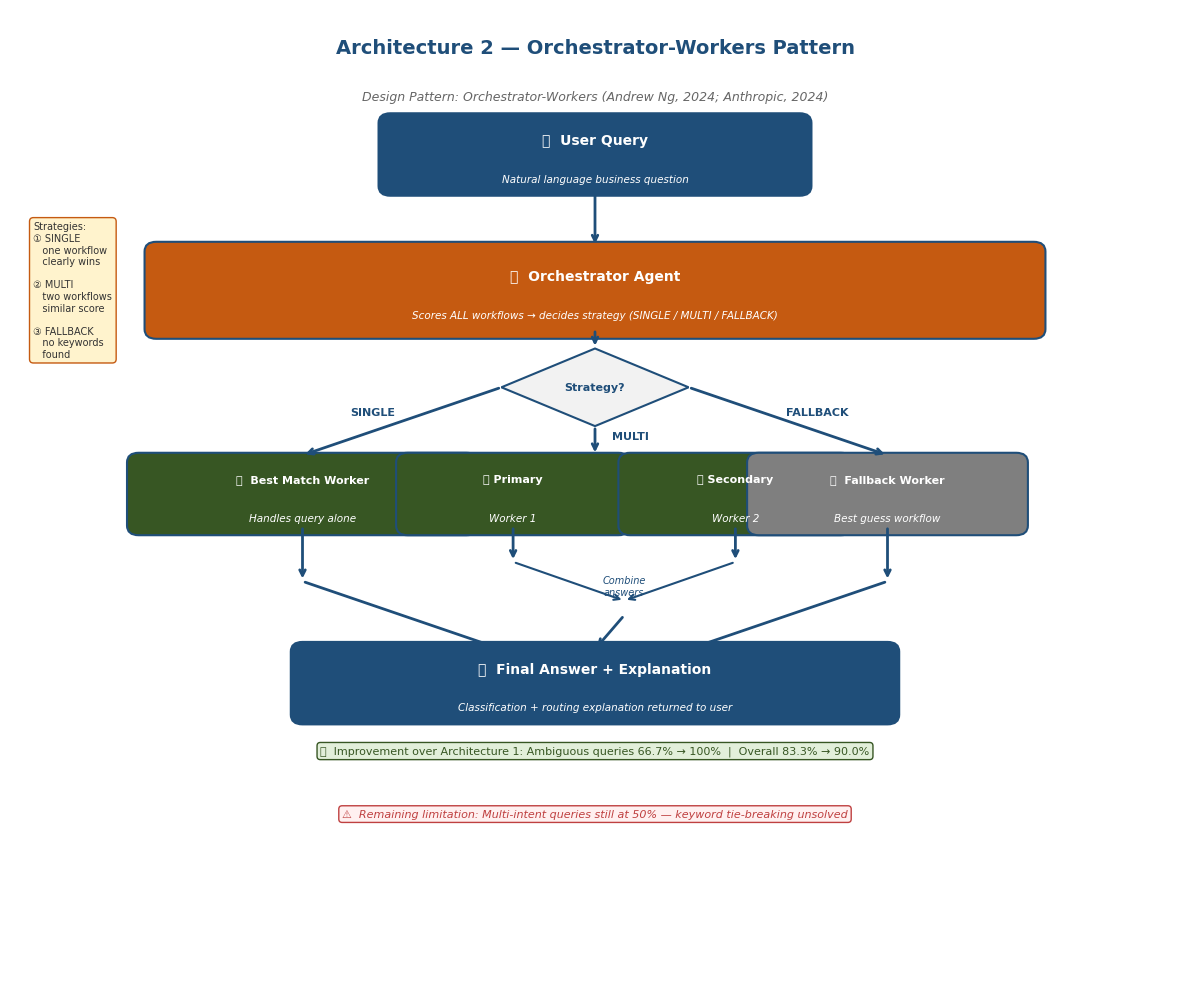


✓ Architecture 2 diagram saved to:
  /content/drive/MyDrive/Dissertation/Results/arch2_diagram.png


In [11]:
# Cell 10 - Architecture 2 Diagram
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(1, 1, figsize=(12, 10))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

# Title
ax.text(5, 9.6, 'Architecture 2 — Orchestrator-Workers Pattern',
        ha='center', va='center', fontsize=14,
        fontweight='bold', color='#1F4E79')
ax.text(5, 9.1, 'Design Pattern: Orchestrator-Workers '
        '(Andrew Ng, 2024; Anthropic, 2024)',
        ha='center', va='center', fontsize=9,
        color='#666666', style='italic')

# ── Helpers ──────────────────────────────────────────────
def draw_box(ax, x, y, w, h, label, sublabel='',
             facecolor='#2E75B6', textcolor='white',
             fontsize=10):
    box = mpatches.FancyBboxPatch(
        (x - w/2, y - h/2), w, h,
        boxstyle="round,pad=0.1",
        facecolor=facecolor,
        edgecolor='#1F4E79', linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(x, y + (0.15 if sublabel else 0), label,
            ha='center', va='center', fontsize=fontsize,
            fontweight='bold', color=textcolor)
    if sublabel:
        ax.text(x, y - 0.25, sublabel,
                ha='center', va='center', fontsize=7.5,
                color=textcolor, style='italic')

def draw_arrow(ax, x1, y1, x2, y2, color='#1F4E79'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(
                    arrowstyle='->', color=color, lw=2.0))

def draw_label(ax, x, y, text, color='#1F4E79'):
    ax.text(x, y, text, ha='center', va='center',
            fontsize=8, color=color, fontweight='bold')

# ── USER QUERY ───────────────────────────────────────────
draw_box(ax, 5, 8.5, 3.5, 0.65,
         '💬  User Query',
         'Natural language business question',
         facecolor='#1F4E79')
draw_arrow(ax, 5, 8.17, 5, 7.55)

# ── ORCHESTRATOR ─────────────────────────────────────────
draw_box(ax, 5, 7.1, 7.5, 0.8,
         '🧠  Orchestrator Agent',
         'Scores ALL workflows → decides strategy '
         '(SINGLE / MULTI / FALLBACK)',
         facecolor='#C55A11')

# Strategy box
ax.text(0.2, 7.1,
        'Strategies:\n'
        '① SINGLE\n   one workflow\n   clearly wins\n\n'
        '② MULTI\n   two workflows\n   similar score\n\n'
        '③ FALLBACK\n   no keywords\n   found',
        ha='left', va='center', fontsize=7,
        color='#333333',
        bbox=dict(boxstyle='round,pad=0.4',
                  facecolor='#FFF3CD',
                  edgecolor='#C55A11', linewidth=1))

# ── DECISION DIAMOND ─────────────────────────────────────
diamond_x, diamond_y = 5, 6.1
diamond = plt.Polygon(
    [[diamond_x, diamond_y+0.4],
     [diamond_x+0.8, diamond_y],
     [diamond_x, diamond_y-0.4],
     [diamond_x-0.8, diamond_y]],
    facecolor='#F2F2F2',
    edgecolor='#1F4E79', linewidth=1.5
)
ax.add_patch(diamond)
ax.text(diamond_x, diamond_y, 'Strategy?',
        ha='center', va='center',
        fontsize=8, fontweight='bold', color='#1F4E79')

draw_arrow(ax, 5, 6.7, 5, 6.5)

# ── THREE PATHS ──────────────────────────────────────────

# Path 1: SINGLE (left)
draw_arrow(ax, 4.2, 6.1, 2.5, 5.4)
draw_label(ax, 3.1, 5.85, 'SINGLE')

# Path 2: MULTI (centre)
draw_arrow(ax, 5, 5.7, 5, 5.4)
draw_label(ax, 5.3, 5.6, 'MULTI')

# Path 3: FALLBACK (right)
draw_arrow(ax, 5.8, 6.1, 7.5, 5.4)
draw_label(ax, 6.9, 5.85, 'FALLBACK')

# ── SINGLE PATH ──────────────────────────────────────────
draw_box(ax, 2.5, 5.0, 2.8, 0.65,
         '👤  Best Match Worker',
         'Handles query alone',
         facecolor='#375623', fontsize=8)
draw_arrow(ax, 2.5, 4.67, 2.5, 4.1)

# ── MULTI PATH ───────────────────────────────────────────
draw_box(ax, 4.3, 5.0, 1.8, 0.65,
         '👤 Primary',
         'Worker 1',
         facecolor='#375623', fontsize=8)
draw_box(ax, 6.2, 5.0, 1.8, 0.65,
         '👥 Secondary',
         'Worker 2',
         facecolor='#375623', fontsize=8)
draw_arrow(ax, 4.3, 4.67, 4.3, 4.3)
draw_arrow(ax, 6.2, 4.67, 6.2, 4.3)

# Combine arrow
ax.annotate('', xy=(5.25, 3.9),
            xytext=(4.3, 4.3),
            arrowprops=dict(arrowstyle='->',
                            color='#1F4E79', lw=1.5))
ax.annotate('', xy=(5.25, 3.9),
            xytext=(6.2, 4.3),
            arrowprops=dict(arrowstyle='->',
                            color='#1F4E79', lw=1.5))
ax.text(5.25, 4.05, 'Combine\nanswers',
        ha='center', va='center',
        fontsize=7, color='#1F4E79', style='italic')

# ── FALLBACK PATH ────────────────────────────────────────
draw_box(ax, 7.5, 5.0, 2.2, 0.65,
         '🔄  Fallback Worker',
         'Best guess workflow',
         facecolor='#7F7F7F', fontsize=8)
draw_arrow(ax, 7.5, 4.67, 7.5, 4.1)

# ── COMBINED RESULT ──────────────────────────────────────
draw_arrow(ax, 2.5, 4.1, 4.2, 3.4)
draw_arrow(ax, 5.25, 3.75, 5.0, 3.4)
draw_arrow(ax, 7.5, 4.1, 5.8, 3.4)

draw_box(ax, 5, 3.05, 5.0, 0.65,
         '✅  Final Answer + Explanation',
         'Classification + routing explanation returned to user',
         facecolor='#1F4E79')

# ── IMPROVEMENT NOTE ─────────────────────────────────────
ax.text(5, 2.35,
        '✅  Improvement over Architecture 1: '
        'Ambiguous queries 66.7% → 100%  |  '
        'Overall 83.3% → 90.0%',
        ha='center', va='center', fontsize=8,
        color='#375623',
        bbox=dict(boxstyle='round,pad=0.3',
                  facecolor='#E2EFDA',
                  edgecolor='#375623', linewidth=1))

# ── REMAINING LIMITATION ─────────────────────────────────
ax.text(5, 1.7,
        '⚠  Remaining limitation: '
        'Multi-intent queries still at 50% — '
        'keyword tie-breaking unsolved',
        ha='center', va='center', fontsize=8,
        color='#BF4040', style='italic',
        bbox=dict(boxstyle='round,pad=0.3',
                  facecolor='#FFF0F0',
                  edgecolor='#BF4040', linewidth=1))

plt.tight_layout()

# Save
diagram_path = f"{results_path}/arch2_diagram.png"
plt.savefig(diagram_path, dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()

print(f"\n✓ Architecture 2 diagram saved to:")
print(f"  {diagram_path}")